# Лабораторная работа 4. Классификация и метрики качества

**Версия для студентов: в частях 4 и 7 нужно дописать код.**

**Курс «Машинное обучение», 4 курс** · после лекции 3

На проверку пришли 200 человек. Больных среди них 10.
Программа коллеги пишет: «95% ответов верные».

Вопрос занятия: **кого из десятерых она нашла?**

Модель отвечает числом от 0 до 1 — вероятностью класса «болен».
Порог превращает это число в ответ «болен» или «здоров».
От порога зависит, кого пропустим, а доля верных ответов этого не показывает.

| Часть | Тема |
|---|---|
| 1 | Отчёт «95% верных» |
| 2 | Карта вероятностей |
| 3 | Сами двигаем порог |
| 4 | **Пишем логистическую регрессию сами** |
| 5 | SVM: широкая полоса или узкая |
| 6 | Полумесяцы: когда прямой мало |
| 7 | Переписываем отчёт коллеги |

Как работать с ноутбуком:

- перед ячейкой **«Подумайте»** ответьте сами, потом запускайте;
- свёрнутые ячейки готовят данные и рисуют картинки — их достаточно запустить;
- картинки в рамках — шутка к части, числа берите из вывода ячеек.

In [ ]:
# @title Импорты
# Импорты. Эту ячейку достаточно запустить.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    roc_curve,
    roc_auc_score,
)

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (11, 7.2)
plt.rcParams["figure.dpi"] = 60  # меньше — картинки мельче на экране
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 28
plt.rcParams["axes.titlesize"] = 32
plt.rcParams["axes.labelsize"] = 28
plt.rcParams["legend.fontsize"] = 24


def _sig(z):
    # служебная сигмоида для картинок; в части 4 пишете свою
    z = np.clip(z, -30, 30)
    return 1.0 / (1.0 + np.exp(-z))


---
# Часть 1. Отчёт «95% верных»

**Подумайте.** 190 здоровых и 10 больных.
Программа всегда отвечает «здоров».
Какую долю верных ответов она напечатает? Сколько больных найдёт?

Сначала соберём эту выборку.
Класс 0 — здоровые, их 190. Класс 1 — больные, их 10.
У каждого человека два анализа в ммоль/л: глюкоза и холестерин.
Глюкоза у здоровых в среднем около 4.8, у больных около 6 — больные правее.
По холестерину классы почти не различаются.
Точки случайные, но seed зафиксирован: у всех на занятии одна и та же картинка.

In [ ]:
# @title Генерация данных `make_imbalanced`
def make_imbalanced(n_neg=190, n_pos=10, seed=7):
    rng = np.random.default_rng(seed)
    # средние (глюкоза, холестерин) и разброс, ммоль/л
    X0 = rng.normal([4.8, 5.0], [0.6, 1.0], size=(n_neg, 2))
    X1 = rng.normal([6.0, 5.2], [0.6, 1.0], size=(n_pos, 2))
    X = np.vstack([X0, X1])
    y = np.concatenate([np.zeros(n_neg), np.ones(n_pos)])
    return X, y


In [ ]:
X, y = make_imbalanced()
n0 = int((y == 0).sum())
n1 = int((y == 1).sum())
print("здоровых:", n0, " больных:", n1)
print("доля здоровых:", round(n0 / len(y), 2))


Это и есть данные: таблица из 200 строк.
Два столбца — анализы, третий — класс: 0 — «здоров», 1 — «болен».
Больные записаны в конце, поэтому в первых строках их не видно.

In [ ]:
people = pd.DataFrame(X, columns=["глюкоза", "холестерин"])
people["класс"] = y.astype(int)
print("строк:", len(people), " столбцов:", people.shape[1])
print(people.head(5).round(2).to_string())
print("...")
print(people.tail(5).round(2).to_string())


Те же 200 строк на плоскости.
Красные точки — больные, их десять. Синих гораздо больше.


In [ ]:
# @title Рисунок: Те же 200 строк
plt.figure(figsize=(9, 6.6))
plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    s=12, c="#2166ac", label="здоровые",
)
plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    s=42, c="#b2182b", label="больные",
)
plt.xlabel("глюкоза")
plt.ylabel("холестерин")
plt.legend()
plt.title("Те же 200 строк")
plt.show()


Программа коллеги на анализы не смотрит и всем отвечает 0, то есть «здоров».
`np.zeros_like(y)` — массив нулей той же длины, что и `y`.

Доля верных ответов (accuracy) — доля совпадений ответа с истинным классом.

In [ ]:
y_const = np.zeros_like(y)
print("доля верных:", round((y_const == y).mean(), 2))
print(confusion_matrix(y, y_const))
print("recall:", recall_score(y, y_const))
print("precision:", precision_score(y, y_const, zero_division=0))

Та же матрица картинкой.
Синяя клетка — верный ответ, красная — ошибка.

In [ ]:
# @title Функция для рисунка `show_matrix`
def show_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.axis("off")
    text = [
        [
            "верно «здоров» (TN)\n%d" % cm[0, 0],
            "ложная тревога (FP)\n%d" % cm[0, 1],
        ],
        [
            "пропуск (FN)\n%d" % cm[1, 0],
            "верно «болен» (TP)\n%d" % cm[1, 1],
        ],
    ]
    drawn = ax.table(
        cellText=text,
        rowLabels=["здоров", "болен"],
        colLabels=["сказали «здоров»", "сказали «болен»"],
        loc="center",
        cellLoc="center",
    )
    drawn.auto_set_font_size(False)
    drawn.set_fontsize(26)
    drawn.scale(1.15, 5.2)
    drawn[1, 0].set_facecolor("#d6e6f5")
    drawn[1, 1].set_facecolor("#f6c9c4")
    drawn[2, 0].set_facecolor("#f6c9c4")
    drawn[2, 1].set_facecolor("#d6e6f5")
    ax.set_title(title, pad=18)
    plt.tight_layout()
    plt.show()

In [ ]:
show_matrix(
    confusion_matrix(y, y_const),
    "Ответ «всем здоров»",
)


Робот смотрит на стопку верных ответов «здоров» и не видит десятерых.

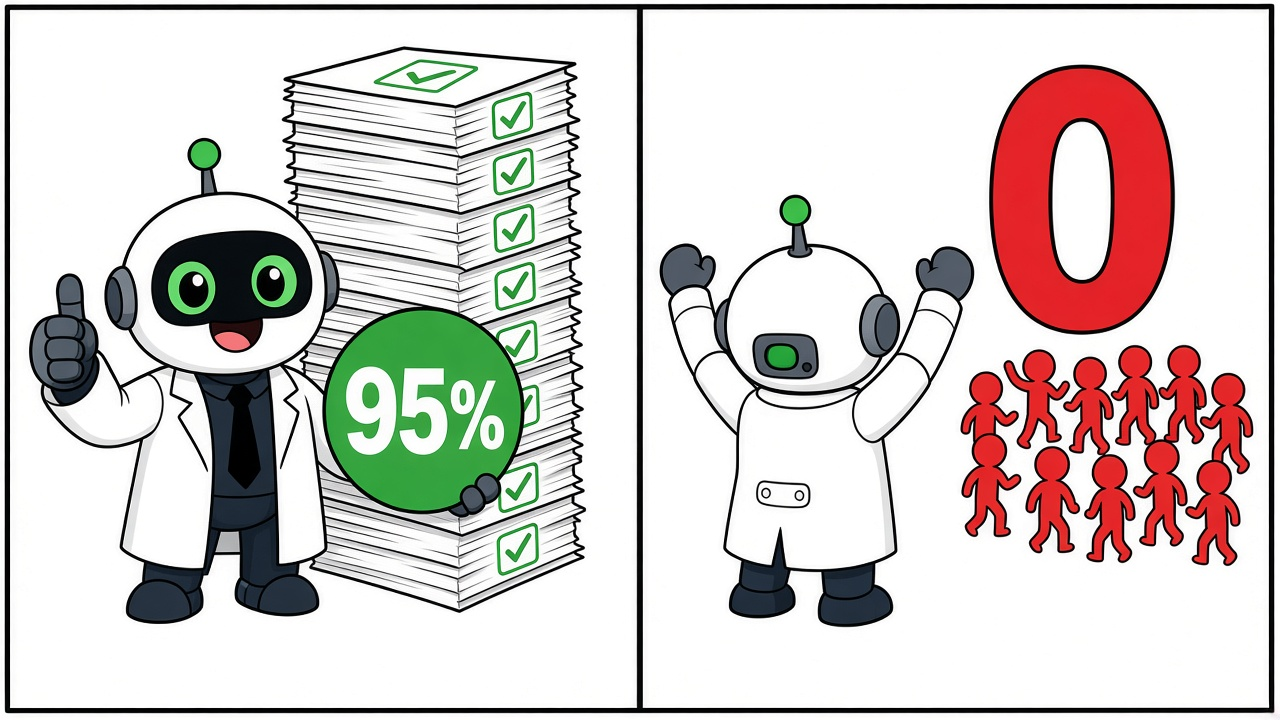

**Что видим.** Доля верных $190/200 = 0{,}95$ — ровно доля здоровых. Найдено больных: 0.
Матрица ошибок

$$
\begin{pmatrix}190 & 0 \\ 10 & 0\end{pmatrix}.
$$

Строка — истинный класс, столбец — ответ программы.
У клеток есть короткие имена, они понадобятся в домашней работе:

| | ответ «здоров» | ответ «болен» |
|---|---|---|
| **здоров** | TN — верно «здоров» | FP — ложная тревога |
| **болен** | FN — пропуск | TP — верно «болен» |

Здесь TN = 190, FP = 0, FN = 10, TP = 0: все десять больных пропущены.

Полнота (recall) — какую долю больных нашли: $TP/(TP+FN) = 0/10 = 0$.
Точность (precision) — какая доля тревог была настоящей: $TP/(TP+FP)$.
Тревог не было, делить не на что, поэтому для precision в коде стоит `zero_division=0`.

Не путайте: «точность» в машинном обучении — это precision.
Долю всех верных ответов так и называем — доля верных.

Дальше соберём модель, которая выдаёт вероятность, и сами выберем порог.

---
# Часть 2. Карта вероятностей

Те же 200 человек. Вместо ответа «всем здоров» учим логистическую регрессию.
Она отвечает не «да» или «нет», а вероятностью класса «болен»:

$$
P(\text{болен}) = \sigma(w_1 x_1 + w_2 x_2 + b),
\qquad
\sigma(z) = \frac{1}{1 + e^{-z}}.
$$

Здесь $x_1$ — глюкоза, $x_2$ — холестерин.
Сигмоида $\sigma$ переводит любое число $z$ в вероятность от 0 до 1:
при $z = 0$ получается $1/2$, при больших $z$ — почти 1,
при больших по модулю отрицательных — почти 0.

In [ ]:
# @title Рисунок: Сигмоида
z = np.linspace(-6, 6, 300)
plt.figure(figsize=(10, 5.4))
plt.plot(z, _sig(z), lw=2, color="#2166ac")
plt.scatter([0], [0.5], c="black", zorder=3)
plt.annotate(
    "z = 0, ответ 1/2",
    (0, 0.5),
    textcoords="offset points",
    xytext=(8, 8),
)
plt.xlabel("z")
plt.ylabel("значение сигмоиды")
plt.title("Сигмоида")
plt.ylim(-0.05, 1.05)
plt.show()


Прежде чем учить модель, приведём анализы к одному масштабу.

Стандартизация: из каждого столбца вычитаем его среднее и делим на его разброс.
После этого у обоих анализов среднее 0 и разброс 1.
Здесь разброс у анализов и так одного порядка.
В домашней работе признаки различаются в сотни раз.
Без стандартизации шаг спуска приходится подбирать под признак с самыми большими числами,
и веса остальных признаков сдвигаются очень медленно.

Столбец единиц — свободный член $b$. Его добавляем **после** стандартизации:
разброс у столбца единиц нулевой, и стандартизация поделила бы на ноль.

In [ ]:
mu = X.mean(axis=0)
sd = X.std(axis=0)
print("средние:", mu)
print("разброс:", sd)


In [ ]:
Xs = (X - mu) / sd
print("средние после:", Xs.mean(axis=0))
print("разброс после:", Xs.std(axis=0))


In [ ]:
ones = np.ones(len(X))
Xb = np.column_stack([ones, Xs])
print("размер Xb:", Xb.shape)
print("первая строка:", Xb[0])


`LogisticRegression` находит те же веса, которые в части 4 вы получите своим спуском.
`penalty=None` — без штрафа на веса.
`fit_intercept=False` — свободный член уже лежит в первом столбце,
второй раз его добавлять не нужно.

`score` — доля верных ответов при пороге 0.5.

In [ ]:
sk = LogisticRegression(
    penalty=None,
    fit_intercept=False,
    max_iter=2000,
)
sk.fit(Xb, y)
print("веса:", sk.coef_.ravel())
print("доля верных при пороге 0.5:", round(sk.score(Xb, y), 3))


Весов три: свободный член, вес глюкозы, вес холестерина.
У глюкозы вес большой и положительный: больные заметно правее.
У холестерина вес маленький и даже отрицательный:
по холестерину больные почти не отличаются от здоровых.
Знак здесь случаен — по десяти больным такой слабый эффект не различить.
Вывод «холестерин защищает» из модели не следует.

`prob` — вероятность «болен» для каждого из 200 человек.
Она понадобится до конца занятия.

In [ ]:
prob = sk.predict_proba(Xb)[:, 1]
print("минимальная вероятность:", round(float(prob.min()), 3))
print("максимальная вероятность:", round(float(prob.max()), 3))


Карта ниже — та же модель на сетке 200 на 200 точек.

Модель училась на стандартизованных числах, а оси оставляем в ммоль/л.
Поэтому каждую точку сетки стандартизуем теми же `mu` и `sd`,
добавляем столбец единиц и спрашиваем вероятность.
Граница от этого не перестаёт быть прямой: стандартизация только сдвигает и растягивает оси.

In [ ]:
x1 = np.linspace(X[:, 0].min() - 0.25, X[:, 0].max() + 0.25, 200)
x2 = np.linspace(X[:, 1].min() - 0.4, X[:, 1].max() + 0.4, 200)
g1, g2 = np.meshgrid(x1, x2)
grid = np.column_stack([g1.ravel(), g2.ravel()])
print("точек на карте:", len(grid))


In [ ]:
z = (grid - mu) / sd
z = np.column_stack([np.ones(len(grid)), z])
prob_map = sk.predict_proba(z)[:, 1]
zz = prob_map.reshape(g1.shape)
print("вероятности от", round(zz.min(), 3), "до", round(zz.max(), 3))


In [ ]:
# @title Рисунок: Чёрная линия — порог 0.5
plt.figure(figsize=(9.5, 7.2))
plt.contourf(g1, g2, zz, levels=np.linspace(0, 1, 11), cmap="RdBu_r")
plt.colorbar(label="P(болен)")
plt.contour(g1, g2, zz, levels=[0.5], colors="black", linewidths=2.5)
plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    s=22, c="#2166ac", label="здоровые",
    edgecolors="white", linewidths=0.6,
)
plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    s=70, c="#b2182b", label="больные",
    edgecolors="white", linewidths=1.2,
)
plt.xlabel("глюкоза")
plt.ylabel("холестерин")
plt.legend(loc="upper left")
plt.title("Чёрная линия — порог 0.5")
plt.show()


**Что видим.** Цвет — вероятность «болен».
Чёрная линия — точки, где вероятность равна 0.5.
Далеко от линии цвет почти красный или почти синий: там модель уверена.

Граница прямая: внутри сигмоиды стоит линейная функция $w_1 x_1 + w_2 x_2 + b$.

Линия прижата к правому краю облака больных.
Больных всего десять, и модель не спешит говорить «болен»:
пятеро из десяти остались по синюю сторону линии.

---
# Часть 3. Сами двигаем порог

Правило ответа: если вероятность $\ge t$, говорим «болен», иначе «здоров».
Порог $t = 0{,}5$ ниоткуда не следует: это просто место,
где оба класса для модели равновероятны.
Двигаем порог и смотрим, кого находим. Сначала порог 0.5.

In [ ]:
pred05 = (prob >= 0.5).astype(int)
print(confusion_matrix(y, pred05))
print("recall", round(recall_score(y, pred05), 2))
print("precision", round(precision_score(y, pred05), 2))


In [ ]:
show_matrix(
    confusion_matrix(y, pred05),
    "Порог 0.5",
)


Верхняя строка: верно «здоров» и одна ложная тревога, FP = 1.
Нижняя: пять пропусков и пять найденных больных, FN = 5, TP = 5.
Полнота $5/10 = 0{,}50$. Точность (precision) $5/6 \approx 0{,}83$:
из шести тревог одна была про здорового.

Доля верных при этом 0.97: пятеро пропущенных почти не влияют на неё, их мало.

Теперь опустим порог: 0.3, 0.15, 0.08.

In [ ]:
print("порог   доля_верных   recall   precision   FP   FN")
for t in (0.5, 0.3, 0.15, 0.08):
    pred = (prob >= t).astype(int)
    acc = (pred == y).mean()
    rec = recall_score(y, pred)
    prec = precision_score(y, pred, zero_division=0)
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    print(
        f"{t:5.2f}   {acc:11.3f}   {rec:6.2f}"
        f"   {prec:9.2f}   {fp:3d}   {fn:3d}"
    )


Красные точки — десять больных, синие — здоровые.
Розовая зона справа от черты — ответ «болен».
Синяя точка в розовой зоне — ложная тревога.
Черта едет влево: в зону попадает больше больных и больше здоровых.


In [ ]:
# @title Рисунок: четыре порога на шкале вероятностей
fig, axes = plt.subplots(1, 4, figsize=(18, 8), sharey=True)
sick = prob[y == 1]
healthy = prob[y == 0]
for ax, t in zip(axes, (0.5, 0.3, 0.15, 0.08)):
    ax.axvspan(t, 1, color="#f6c9c4", alpha=0.55)
    ax.scatter(
        healthy, np.zeros(len(healthy)),
        s=40, c="#2166ac", alpha=0.45, zorder=3,
    )
    ax.scatter(
        sick, np.ones(len(sick)),
        s=90, c="#b2182b", zorder=3,
    )
    ax.axvline(t, color="black", lw=1.2)
    found = int((sick >= t).sum())
    ax.set_title(
        "порог %g\nбольных %d/10" % (t, found),
        pad=14,
    )
    ax.set_xlim(-0.02, 1.02)
fig.supxlabel("вероятность")
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["здоровые", "больные"])
plt.tight_layout()
fig.subplots_adjust(left=0.12, bottom=0.16)
plt.show()


Высокий забор 0.5: часть больных осталась внизу, здоровый почти не пролез.
Низкий забор 0.15: больные прошли, и здоровые тоже.

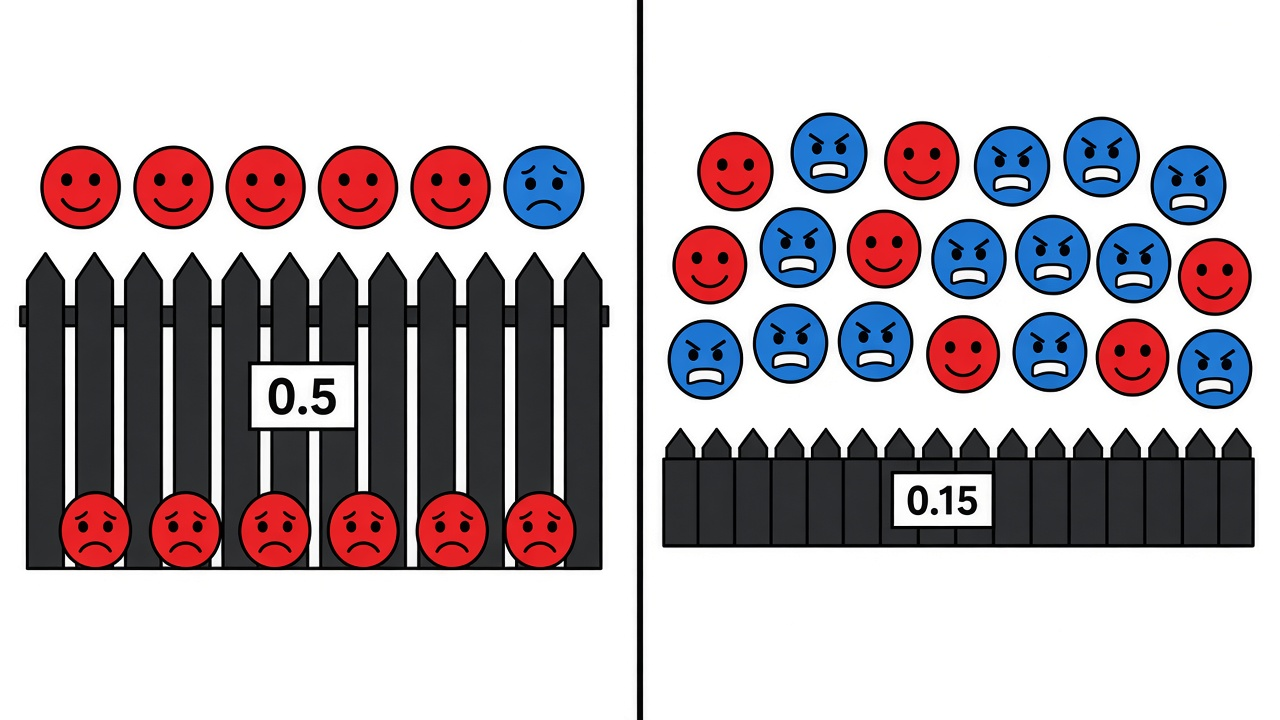

**Что видим.**

- Порог 0.5: доля верных 0.97, полнота 0.50, одна ложная тревога (FP) и пять пропусков (FN).
- Порог 0.15: полнота 0.80, ложных тревог уже 8. Из тревог настоящая примерно каждая вторая.
- Порог 0.08: полнота та же 0.80, ложных тревог 15, доля верных падает до 0.915.

Полноту покупают лишними проверками.
Какой обмен приемлем, решает задача.
В домашней работе пропустить опухоль хуже, чем лишний раз перепроверить,
поэтому полноту требуют не ниже 0.95.


Те же два порога на карте из части 2.
Сплошная линия — порог 0.5, пунктир — порог 0.15.
Пунктир левее: за ним оказались ещё трое больных и семеро здоровых.


In [ ]:
# @title Рисунок: два порога на карте
plt.figure(figsize=(9.5, 7.2))
plt.contourf(g1, g2, zz, levels=np.linspace(0, 1, 11), cmap="RdBu_r")
plt.colorbar(label="P(болен)")
plt.contour(g1, g2, zz, levels=[0.5], colors="black", linewidths=2.5)
plt.contour(
    g1, g2, zz, levels=[0.15],
    colors="black", linestyles="dashed", linewidths=2.5,
)
plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    s=22, c="#2166ac", label="здоровые",
    edgecolors="white", linewidths=0.6,
)
plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    s=70, c="#b2182b", label="больные",
    edgecolors="white", linewidths=1.2,
)
plt.xlabel("глюкоза")
plt.ylabel("холестерин")
plt.legend(loc="upper left")
plt.title("Порог 0.5 и порог 0.15")
plt.show()


На лекции кривой ROC не было. Соберём её сами из таблицы выше.

У порога два числа, оба — доли.
Первое: сколько здоровых назвали больными, делённое на всех здоровых (их 190).
Второе: полнота — сколько больных нашли, делённое на всех больных (их 10).
Четыре порога дают четыре точки.

In [ ]:
n0 = int((y == 0).sum())
n1 = int((y == 1).sum())
print("порог   ложные/здоровые   полнота")
xs, ys = [], []
for t in (0.5, 0.3, 0.15, 0.08):
    pred = (prob >= t).astype(int)
    fp = int(((pred == 1) & (y == 0)).sum())
    tp = int(((pred == 1) & (y == 1)).sum())
    xs.append(fp / n0)
    ys.append(tp / n1)
    print(
        f"{t:5.2f}   {fp:2d}/{n0} = {fp / n0:5.3f}"
        f"     {tp / n1:4.2f}"
    )

In [ ]:
# @title Рисунок: Четыре порога
plt.figure(figsize=(8, 8))
plt.plot(xs, ys, "o", color="#b2182b", ms=9)
for t, px, py in zip((0.5, 0.3, 0.15, 0.08), xs, ys):
    plt.annotate(
        f"{t:.2f}",
        (px, py),
        textcoords="offset points",
        xytext=(8, 4),
    )
plt.plot([0, 1], [0, 1], color="gray", lw=1)
plt.xlim(-0.02, 1)
plt.ylim(0, 1.02)
plt.xlabel("доля ложных тревог среди здоровых")
plt.ylabel("полнота")
plt.title("Четыре порога")
plt.show()


Вправо на графике — больше ложных тревог среди здоровых.
Вверх — больше найденных больных.
Удачная точка стояла бы в левом верхнем углу:
всех больных нашли и никого здорового не задели.
Четыре порога туда не попали.

Если перебрать все возможные пороги, точки сольются в кривую — её называют ROC.
Площадь под ней (ROC-AUC) — одно число сразу по всем порогам.
Площадь 1: у каждого больного вероятность выше, чем у каждого здорового.
Площадь 0.5: порядок вероятностей не лучше случайного.

In [ ]:
fpr, tpr, _ = roc_curve(y, prob)
area = roc_auc_score(y, prob)
print("площадь под кривой =", round(area, 3))


In [ ]:
# @title Рисунок: Все пороги, кривая ROC
plt.figure(figsize=(8, 8))
plt.plot(fpr, tpr, lw=2, label=f"площадь = {area:.3f}")
plt.plot([0, 1], [0, 1], color="gray", lw=1, label="диагональ, площадь 0.5")
plt.xlabel("доля ложных тревог среди здоровых")
plt.ylabel("полнота")
plt.title("Все пороги, кривая ROC")
plt.legend(loc="lower right")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


**Что видим.** Четыре точки легли на кривую, площадь равна 0.955.
Диагональ — площадь 0.5. Там оказался бы ответ «всем здоров» из части 1,
хотя доля верных у него 0.95.

---
# Часть 4. Пишем логистическую регрессию сами

Веса в части 2 нашёл `sklearn`. Теперь найдём их своим градиентным спуском.

Почему не минимизировать сразу число ошибок?
Потеря «ошибся / не ошибся» равна 0 или 1: наклона у неё почти нигде нет, шагать некуда.

Слева потеря-ступенька: впереди обрыв. Справа гладкая: видно, куда идти.

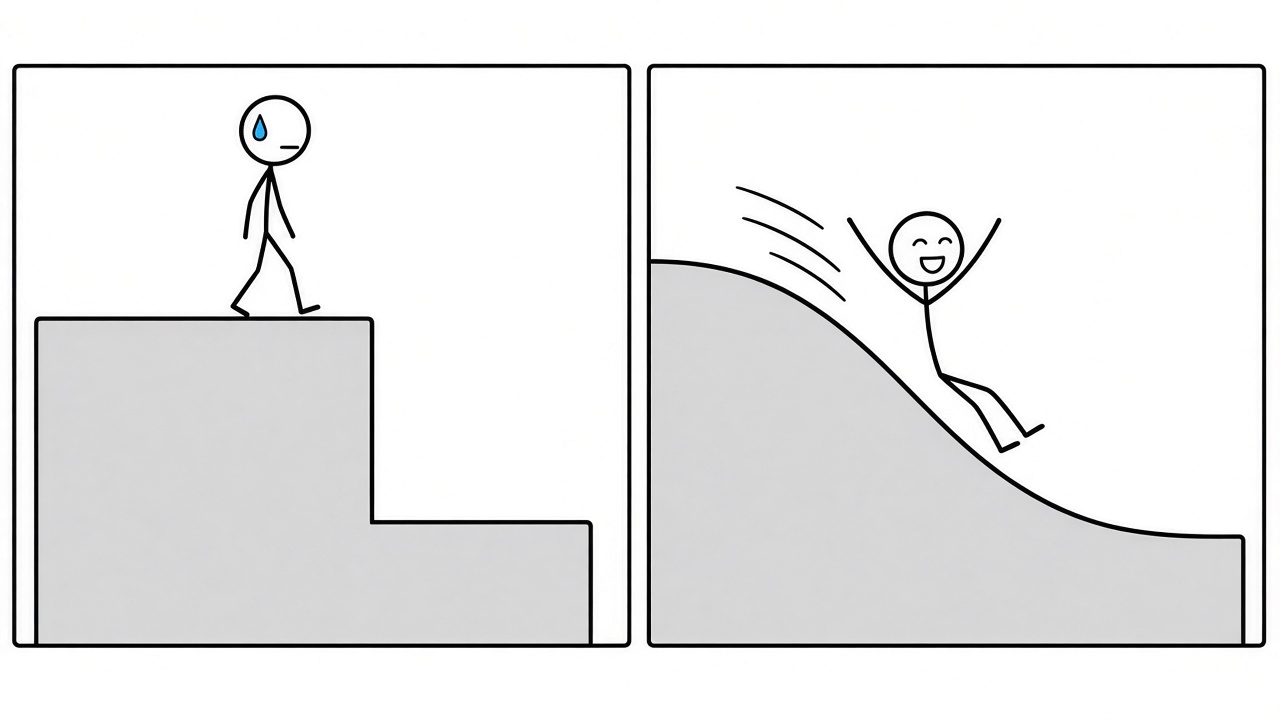

На графике обе потери как функции отступа $M = y\,\theta^{\mathsf T}x$;
для этой картинки класс записан как $\pm 1$.
Большое положительное $M$ — верный уверенный ответ, отрицательное — ошибка.

In [ ]:
# @title Рисунок: две потери
M = np.linspace(-3, 4, 400)
indicator = (M < 0).astype(float)
logistic = np.log1p(np.exp(-M))

plt.figure(figsize=(11, 6.2))
plt.plot(M, indicator, label="индикатор")
plt.plot(M, logistic, label="логистическая")
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("отступ M")
plt.ylabel("потеря")
plt.legend()
plt.show()

**Подумайте.** Пример из лекции.
Три точки, столбец единиц уже стоит в матрице:

$$
X = \begin{pmatrix}1 & 1 \\ 1 & 2 \\ 1 & 3\end{pmatrix},
\quad
y = \begin{pmatrix}0 \\ 1 \\ 1\end{pmatrix}.
$$

Старт $\theta = (0, 0)$, шаг $\eta = 0{,}5$.
Куда сдвинется вторая координата $\theta$ — в плюс или в минус?


In [ ]:
X_ex = np.array([
    [1.0, 1.0],
    [1.0, 2.0],
    [1.0, 3.0],
])
y_ex = np.array([0.0, 1.0, 1.0])
print("X =")
print(X_ex)
print("y =", y_ex)


При $\theta = 0$ аргумент сигмоиды нулевой, а $\sigma(0) = 1/2$:
все три вероятности равны $1/2$.
Здесь работает служебная сигмоида `_sig` из первой ячейки, свою вы напишете ниже.

In [ ]:
theta = np.zeros(2)
h = _sig(X_ex @ theta)
print("h =", h)


Градиент логистической потери — сумма по объектам:

$$
\nabla Q = X^{\mathsf T}(h - y).
$$

Множителя 2, как у квадратичной потери в лабораторной 3, здесь нет.

In [ ]:
grad = X_ex.T @ (h - y_ex)
print("h - y =", h - y_ex)
print("градиент =", grad)


Проверка руками. $h - y = (1/2,\ -1/2,\ -1/2)$.

Первая координата градиента — столбец единиц:

$$
1\cdot\frac12 + 1\cdot\left(-\frac12\right) + 1\cdot\left(-\frac12\right) = -\frac12.
$$

Вторая — столбец $(1, 2, 3)$:

$$
1\cdot\frac12 + 2\cdot\left(-\frac12\right) + 3\cdot\left(-\frac12\right) = -2.
$$

Шаг: $\theta \leftarrow \theta - 0{,}5\cdot\nabla Q$.


In [ ]:
theta = theta - 0.5 * grad
print("theta =", theta)


**Что видим.** После шага $\theta = (0{,}25,\ 1)$.
Вторая координата выросла: градиент по ней отрицательный, а мы его вычитаем.
Так и должно быть: в примере большему $x$ соответствует класс 1.

Теперь тот же шаг в коде, на всех 200 людях:

$$
h = \sigma(X\theta), \qquad
\theta \leftarrow \theta - \eta\,X^{\mathsf T}(h - y).
$$

Не хватает четырёх строк: одной в `sigmoid` и трёх в `logreg_gd`.
Потеря `log_loss` и запись истории `losses` уже готовы.

In [ ]:
# ✍ ЗАДАНИЕ НА СЕМИНАРЕ
def sigmoid(z):
    z = np.clip(z, -30, 30)   # обрезка, чтобы exp не переполнился
    return ...                # 1 / (1 + exp(-z))

In [ ]:
# Готово: средняя логистическая потеря. Только запустить.
def log_loss(X, y, theta):
    h = sigmoid(X @ theta)
    loss = y * np.log(h + 1e-12)
    loss = loss + (1 - y) * np.log(1 - h + 1e-12)
    return -np.mean(loss)

In [ ]:
# ✍ ЗАДАНИЕ НА СЕМИНАРЕ
def logreg_gd(X, y, eta, n_iter):
    theta = np.zeros(X.shape[1])
    losses = [log_loss(X, y, theta)]   # потеря на старте
    for _ in range(n_iter):
        h = ...       # вероятности: сигмоида от X @ theta
        grad = ...    # градиент: X.T @ (h - y), без множителя 2
        theta = ...   # шаг: theta минус eta на градиент
        losses.append(log_loss(X, y, theta))
    return theta, np.array(losses)

Шаг $\eta = 2/\lambda_{\max}(X^{\mathsf T}X)$ дан готовым: $\lambda_{\max}$ — наибольшее собственное число $X^{\mathsf T}X$, выводить формулу не нужно.

In [ ]:
try:
    lam = np.linalg.eigvalsh(Xb.T @ Xb).max()
    eta = 2.0 / lam
    theta_hat, losses = logreg_gd(Xb, y, eta, n_iter=2000)
    print("веса спуска ", theta_hat)
    print("веса sklearn", sk.coef_.ravel())
except Exception as e:
    print("спуск ещё не готов:", type(e).__name__)

In [ ]:
# Проверка. Не меняйте эту ячейку.
try:
    th, ls = logreg_gd(X_ex, y_ex, eta=0.5, n_iter=1)
    ok_step = np.allclose(th, [0.25, 1.0]) and len(ls) == 2
    print("шаг лекции:", th, "верно" if ok_step else "НЕ совпало")

    lam = np.linalg.eigvalsh(Xb.T @ Xb).max()
    th2, ls2 = logreg_gd(Xb, y, eta=2.0 / lam, n_iter=2000)
    dist = np.linalg.norm(th2 - sk.coef_.ravel())
    ok = ok_step and len(ls2) == 2001 and dist < 0.05
    print("расстояние до sklearn:", round(dist, 4))
    print("длина losses:", len(ls2))
    print("верно" if ok else "что-то не так")
except Exception as e:
    print("функция ещё не готова:", type(e).__name__)


**Ожидаемо.** Расстояние до весов sklearn около 0.001.
Потеря падает от 0.693 к 0.088. Проверка печатает «верно».

Если проверка не прошла:

- в градиенте осталась двойка — шаг лекции даст $(0{,}5,\ 2)$;
- градиент поделили на $n$ — шаг лекции даст $(0{,}08,\ 0{,}33)$;
- вместо сигмоиды написали $X\theta$.

In [ ]:
# @title Рисунок: Потеря на спуске
try:
    plt.figure(figsize=(10, 5.6))
    plt.plot(losses)
    plt.xlabel("итерация")
    plt.ylabel("средняя потеря")
    plt.title("Потеря на спуске")
    plt.show()
except NameError:
    print("график появится, когда спуск заработает")


Две новые точки — звёзды на рисунке.
$(5{,}4;\ 5{,}1)$ лежит посередине между облаками, $(6{,}0;\ 5{,}2)$ — в центре облака больных.
Какую вероятность «болен» им дадут ваш `sigmoid` и веса спуска?

In [ ]:
# @title Рисунок: Две новые точки
plt.figure(figsize=(9, 6.6))
plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    s=12, c="#2166ac", label="здоровые",
)
plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    s=42, c="#b2182b", label="больные",
)
plt.scatter(
    [5.4], [5.1],
    s=160, marker="*", c="black", label="между облаками",
)
plt.scatter(
    [6.0], [5.2],
    s=160, marker="*", c="#fdae61", label="центр больных",
)
plt.xlabel("глюкоза")
plt.ylabel("холестерин")
plt.legend()
plt.title("Две новые точки")
plt.show()


In [ ]:
try:
    def prob_hat(xy):
        z = (xy - mu) / sd
        z = np.column_stack([np.ones(len(xy)), z])
        return sigmoid(z @ theta_hat)

    middle = np.array([[5.4, 5.1]])
    inside = np.array([[6.0, 5.2]])
    print("между облаками:", round(float(prob_hat(middle)[0]), 3))
    print("центр больных:", round(float(prob_hat(inside)[0]), 3))
except Exception:
    print("прогноз появится, когда спуск заработает")


**Что видим.** Посередине между облаками вероятность 0.04.
Даже в центре облака больных — 0.42, меньше половины.
Больных мало, и модель сдвинула линию 0.5 к их краю.
Поэтому в части 3 порог пришлось опускать.

---
# Часть 5. SVM: широкая полоса или узкая

SVM (support vector machine, метод опорных векторов) — ещё один способ провести прямую между классами.

**Идея.** Прямых, которые разделяют два облака, много.
SVM выбирает ту, вокруг которой остаётся **самая широкая пустая полоса** — как дорога между двумя деревнями.
Прямая идёт по середине дороги, подальше от обоих классов,
поэтому новая точка, чуть отличающаяся от обучающих, не перескочит на чужую сторону.

**Опорные векторы** — точки на краю полосы.
Они упираются в полосу и держат её: прямую задают только они.
Остальные точки можно сдвинуть или убрать — прямая не изменится.
Отсюда и название метода.

**Если без ошибок не разделить** (у нас будет один выброс среди чужих), приходится выбирать:

- широкая полоса, но кто-то стоит внутри неё или на чужой стороне;
- узкая полоса, зато все на своих местах.

Выбор задаёт параметр $C$ — штраф за каждую такую точку-нарушителя.
Малый $C$: нарушителя терпим, полоса широкая.
Большой $C$: штраф дорогой, полоса сжимается, лишь бы нарушителей не было.
Нарушители тоже считаются опорными: они влияют на положение прямой.

**То же формулой** (для справки). Классы обозначены $\pm 1$. Модель считает $f(x) = w^{\mathsf T}x + b$, ответ — знак $f$.
Прямая — уровень $f = 0$, края полосы — $f = -1$ и $f = +1$, ширина полосы $2/\|w\|$. SVM решает задачу

$$
\min_{w,\,b}\ \underbrace{\tfrac12\|w\|^2}_{\text{шире полоса}} + C\sum_i \underbrace{\max\bigl(0,\ 1 - y_i f(x_i)\bigr)}_{\text{штраф нарушителю}}.
$$

Точка за краем полосы со своей стороны ($y_i f(x_i) \ge 1$) штрафа не получает.

Широкая полоса терпит выброс, узкая подстраивается под него.

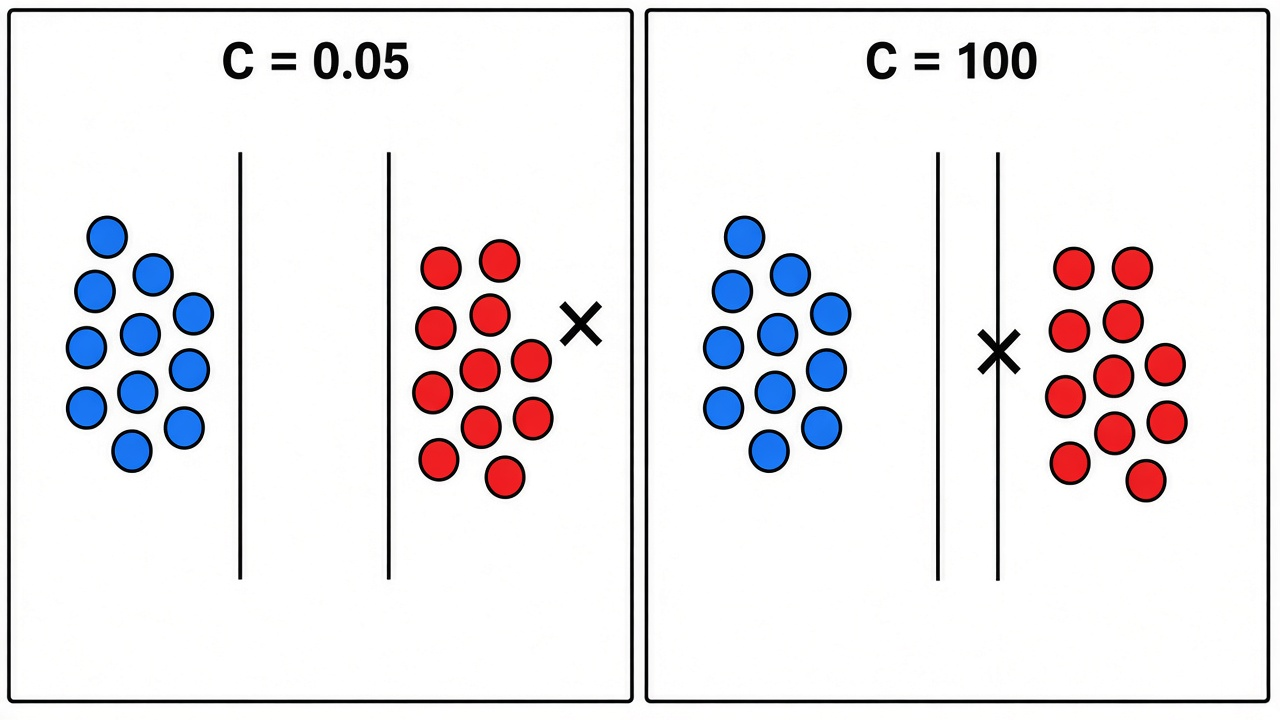

Данные: два облака и одна точка класса −1, попавшая к чужим, — крестик на рисунках.

In [ ]:
rng = np.random.default_rng(2)
A = rng.normal([-1.8, 0.0], 0.35, size=(40, 2))
B = rng.normal([1.8, 0.2], 0.35, size=(40, 2))
outlier = np.array([[0.6, 0.15]])
X_svm = np.vstack([A, B, outlier])
y_svm = np.array([-1] * 40 + [1] * 40 + [-1])
print("точек:", len(y_svm))
print("последняя — выброс класса −1")


Свёрнутая функция `paint_svm` рисует полосу.
Три чёрные линии — уровни $f = -1,\ 0,\ +1$. Кружки — опорные векторы.
В заголовке — ширина полосы.

In [ ]:
# @title Функция для рисунка `paint_svm`
def paint_svm(ax, model, title):
    x1 = np.linspace(
        X_svm[:, 0].min() - 0.4, X_svm[:, 0].max() + 0.4, 200,
    )
    x2 = np.linspace(
        X_svm[:, 1].min() - 0.4, X_svm[:, 1].max() + 0.4, 200,
    )
    g1, g2 = np.meshgrid(x1, x2)
    grid = np.column_stack([g1.ravel(), g2.ravel()])
    dec = model.decision_function(grid).reshape(g1.shape)

    ax.contourf(g1, g2, dec, levels=12, cmap="RdBu_r", alpha=0.85)
    ax.contour(g1, g2, dec, levels=[-1, 0, 1], colors="black")
    ax.scatter(
        X_svm[y_svm == -1, 0], X_svm[y_svm == -1, 1],
        s=18, c="#2166ac",
    )
    ax.scatter(
        X_svm[y_svm == 1, 0], X_svm[y_svm == 1, 1],
        s=18, c="#b2182b",
    )
    ax.scatter(
        X_svm[model.support_, 0],
        X_svm[model.support_, 1],
        s=80, facecolors="none", edgecolors="black",
        label="опорные",
    )
    ax.scatter([0.6], [0.15], s=70, marker="x", c="black", label="выброс")
    width = 2 / np.linalg.norm(model.coef_)
    ax.set_title(f"{title}, ширина {width:.2f}")
    ax.legend(loc="upper left", fontsize=8)


Сначала малый штраф. Смотрим значение $f$ на крестике.
Плюс значит: модель относит его к классу $+1$, то есть он на чужой стороне.

In [ ]:
model_small = SVC(kernel="linear", C=0.05)
model_small.fit(X_svm, y_svm)
f_out = model_small.decision_function(X_svm[-1:])
print("f на выбросе =", round(float(f_out[0]), 3))

In [ ]:
# @title Рисунок: C = 0.05
fig, ax = plt.subplots(figsize=(8, 6.6))
paint_svm(ax, model_small, "C = 0.05")
plt.tight_layout()
plt.show()


Теперь большой штраф. $f = -1$: крестик лежит ровно на краю полосы, со своей стороны.
Его учли, и полоса из-за него сузилась.

In [ ]:
model_large = SVC(kernel="linear", C=100)
model_large.fit(X_svm, y_svm)
f_out = model_large.decision_function(X_svm[-1:])
print("f на выбросе =", round(float(f_out[0]), 3))

In [ ]:
# @title Рисунок: C = 100
fig, ax = plt.subplots(figsize=(8, 6.6))
paint_svm(ax, model_large, "C = 100")
plt.tight_layout()
plt.show()


**Что видим.**

- $C = 0{,}05$: полоса широкая, около 2.9. Без выброса ширина та же, 2.90:
  он почти ни на что не влияет и остаётся на чужой стороне.
- $C = 100$: полоса узкая, около 0.65: её сжали, чтобы выброс оказался на своей стороне.

$C$ решает, насколько модель подстраивается под отдельные точки.

---
# Часть 6. Полумесяцы: когда прямой мало

В лабораторной 2 кольцо вокруг диска не делилось прямой,
пока не добавили признак $z = x_1^2 + x_2^2$.
Полумесяцы устроены так же: одной прямой их не разделить.
SVM с ядром RBF делает похожую замену сама, новые признаки выписывать не нужно.

Линейка режет оба полумесяца, кривая проходит между ними.

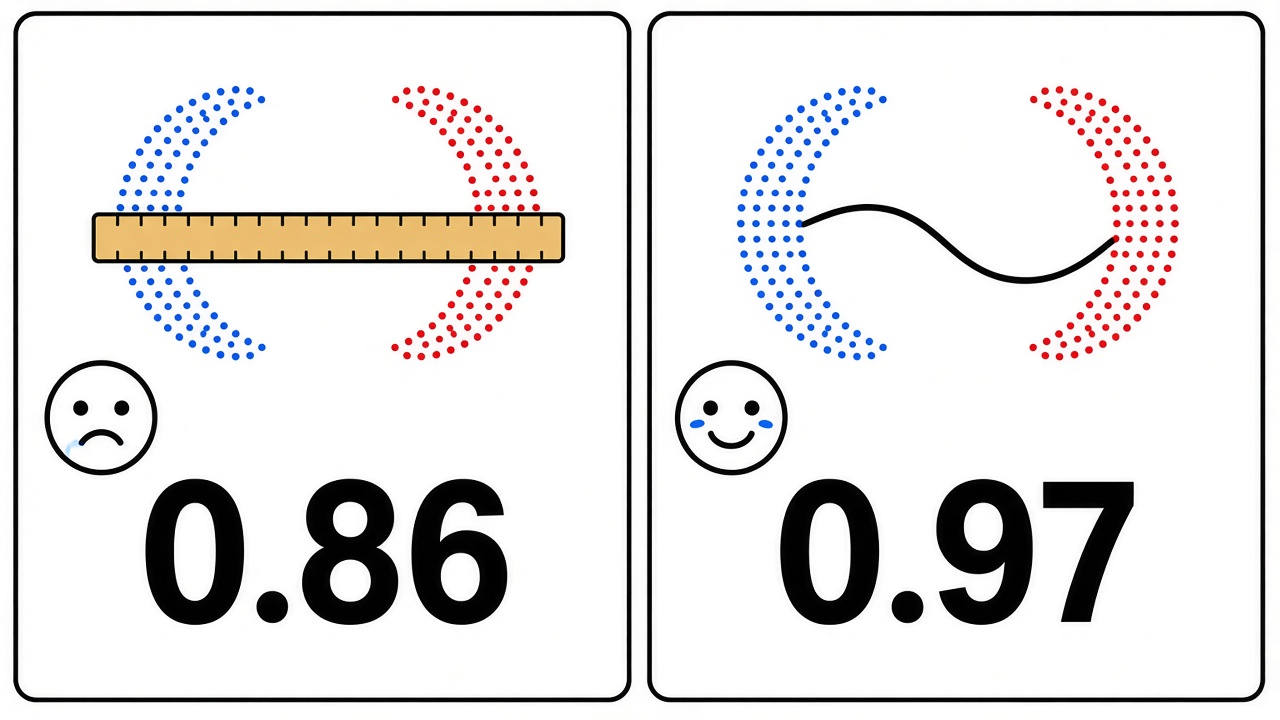

In [ ]:
Xm, ym = make_moons(n_samples=200, noise=0.15, random_state=0)
print("точек:", len(ym))


Свёрнутая функция `paint_kernel` обучает SVM и рисует границу.
Доля верных ответов — в заголовке картинки.

In [ ]:
# @title Функция для рисунка `paint_kernel`
def paint_kernel(ax, X, y, kernel, title):
    model = SVC(kernel=kernel, C=1).fit(X, y)
    x1 = np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 200)
    x2 = np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 200)
    g1, g2 = np.meshgrid(x1, x2)
    grid = np.column_stack([g1.ravel(), g2.ravel()])
    pred = model.predict(grid).reshape(g1.shape)
    ax.contourf(g1, g2, pred, alpha=0.25, cmap="RdBu_r")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=12, c="#2166ac")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=12, c="#b2182b")
    score = model.score(X, y)
    ax.set_title(f"{title}, доля верных {score:.2f}")


In [ ]:
# @title Рисунок: прямая на полумесяцах
fig, ax = plt.subplots(figsize=(8, 6.2))
paint_kernel(ax, Xm, ym, "linear", "прямая")
plt.tight_layout()
plt.show()


Прямая режет оба полумесяца, доля верных 0.86:
часть красных точек на синей стороне, и наоборот.

In [ ]:
# @title Рисунок: RBF на полумесяцах
fig, ax = plt.subplots(figsize=(8, 6.2))
paint_kernel(ax, Xm, ym, "rbf", "RBF")
plt.tight_layout()
plt.show()


**Что видим.** RBF: доля верных 0.97, граница обогнула полумесяцы.

---
# Часть 7. Переписываем отчёт коллеги

Коллега обучил модель из части 2, поставил порог 0.5 и сдал отчёт.

In [ ]:
# Отчёт коллеги. Модель настоящая, порог 0.5.
pred = (prob >= 0.5).astype(int)
acc = (pred == y).mean()
print(f"Доля верных ответов: {acc:.0%}")
print("Модель годится.")


В отчёте одно число и звезда.

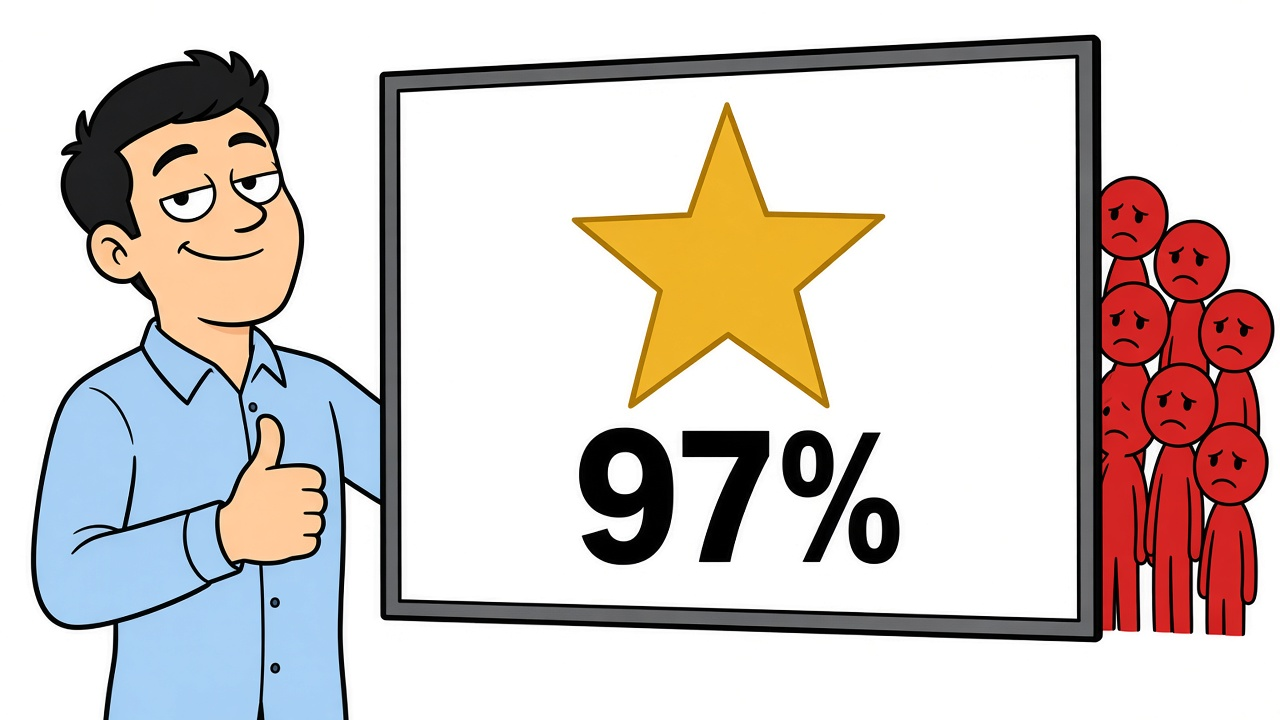

Допишите отчёт: полнота, точность (precision), сколько больных пропущено
и площадь под ROC. Всё это уже встречалось в частях 1–3.

In [ ]:
# ✍ ЗАДАНИЕ НА СЕМИНАРЕ: честный отчёт при пороге 0.5
pred = (prob >= 0.5).astype(int)
print("доля верных:", round((pred == y).mean(), 3))
print("полнота:", ...)               # как в части 3
print("точность (precision):", ...)  # как в части 3
print("пропущено больных:", ...)     # сколько раз y == 1, а pred == 0
print("площадь под ROC:", ...)       # по вероятностям prob, не по ответам

**Подумайте.** Годится ли модель, если пропускать больных нельзя?
Какой порог из таблицы части 3 вы бы предложили и чем за него придётся заплатить?

---
# Домашняя работа 4

Та же логистическая регрессия своим спуском.
Данные — `breast_cancer`, диагноз по снимку ткани.

Положительный класс — **злокачественная опухоль**.
Порог выберите так, чтобы полнота была не ниже 0.95,
и напишите, сколько лишних тревог за это пришлось взять.
У кого-то порог окажется выше 0.5:
полноты уже хватало, и лишнюю тревогу можно убрать.

Разбиение на обучение и тест у каждого своё, по фамилии.

Бонус — SVM с RBF-ядром, небольшая сетка $C$ и $\gamma$.

Идеи обсуждать можно. Код и ответы передавать нельзя.
Работа засчитывается после короткой защиты.
